# 01 · Análisis exploratorio del corpus FakeDeS (IberLEF 2021)

Práctica de **Técnicas Avanzadas de PLN (TAPLN 2026-27)** · tarea: detectar noticias falsas en español (**Fake = clase positiva**, `label = 1`; métrica: F1 sobre Fake; F1 a batir en test: 0.76).

Este notebook es el primer paso del enfoque *LLM + RAG* frente a baselines TF-IDF

**Reglas que se respetan en todo el notebook**
1. `Source` y `Link` **no** se usan como entrada de ningún modelo, solo se emplean para análisis descriptivo y la prueba de control de la sección 11, que existe precisamente para demostrar por qué.
2. Las etiquetas de **test** no se usan para sacar conclusiones ni tomar decisiones; en test solo hay estadísticas sin etiqueta y, al final, la evaluación de la prueba de control.
3. Rutas relativas, `random_state = 42`.

In [1]:
import sys, warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score # Métricas
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# Determinar la raíz del proyecto
ROOT = Path.cwd().resolve()
while not ((ROOT / "data").is_dir() and (ROOT / "src").is_dir()):
    ROOT = ROOT.parent
    
# Importamos nuestras funciones auxiliares 
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu

# Semilla
SEED = eu.SEED
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

# Salida
FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "eda"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

# Estilo de las gráficas
COL = {"Fake": "#D55E00", "True": "#0072B2"}                 # clase
COLS = {"train": "#4D4D4D", "dev": "#009E73", "test": "#CC79A7"}   # conjunto
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 80)

# Funciones auxiliares:

def savefig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

def savetab(df, name, index=True):
    df.to_csv(TAB / name, index=index, encoding="utf-8")

def f1_fake(y, p):
    "Calcula el f1 de fake como clase positiva" 
    return f1_score(y, p, pos_label=1, zero_division=0)

print("Raíz del proyecto:", ROOT.name)

Raíz del proyecto: Practica-TAPLN


## 1 · Carga y comprobaciones

**Verificamos** que los CSV procesados tienen el tamaño, el balance y estructura esperados y **comprobamos** si hay duplicados internos o solapes de texto entre train, dev y test.

In [2]:
# Cargamos los tres .csv
raw = eu.load_splits(ROOT)

# Añadimos las columnas derivadas a los tres ficheros
S = {k: eu.add_base_columns(v) for k, v in raw.items()}
train, dev, test = S["train"], S["dev"], S["test"]

# Comprobar que se sigue el mismo esquema
print("Columnas train/dev/test idénticas:", list(raw["train"].columns) == list(raw["dev"].columns) == list(raw["test"].columns))
print(raw["train"].dtypes.to_string())

# Contamos campos vacíos
vacios = pd.DataFrame({k: (raw[k][["Topic", "Source", "Headline", "Text", "Link"]] == "").sum() for k in S})
print("\nCampos vacíos (cadena vacía; no hay NaN al leer con keep_default_na=False):")
print(vacios)

Columnas train/dev/test idénticas: True
Id           int64
Category       str
Topic          str
Source         str
Headline       str
Text           str
Link           str
label        int64
full_text      str
split          str

Campos vacíos (cadena vacía; no hay NaN al leer con keep_default_na=False):
          train  dev  test
Topic         0    0     0
Source        0    0     7
Headline      0    0    72
Text          0    0     0
Link          0    0     3


In [3]:
def resumen(d):
    "Resumen del dataset"
    n_hl = (d.Headline != "")
    return {
        "filas": len(d), "Fake": int(d.label.sum()), "True": int((1 - d.label).sum()),
        "% Fake": round(100 * d.label.mean(), 1),
        "titulares vacíos": int((~n_hl).sum()), "Source vacío": int((d.Source == "").sum()), "Link vacío": int((d.Link == "").sum()),
        "duplicados Text": int(d.Text.duplicated().sum()),
        "% Text empieza por el titular": round(100 * np.mean([t.startswith(h) for h, t in zip(d.Headline[n_hl], d.Text[n_hl])]), 1),
        "% con *NUMBER*": round(100 * d.Text.str.contains(r"\*NUMBER\*").mean(), 1),
        "% con cifras reales": round(100 * d.Text.str.contains(r"\d").mean(), 1),
    }
    
# Mostrar el resumen en formato dataframe
resumen_df = pd.DataFrame({k: resumen(d) for k, d in S.items()})
savetab(resumen_df, "01_resumen_conjuntos.csv")
resumen_df

,train,dev,test
filas,676.0,291.0,572.0
Fake,338.0,140.0,286.0
True,338.0,151.0,286.0
% Fake,50.0,48.1,50.0
titulares vacíos,0.0,0.0,72.0
Source vacío,0.0,0.0,7.0
Link vacío,0.0,0.0,3.0
duplicados Text,0.0,1.0,0.0
% Text empieza por el titular,97.0,99.0,0.2
% con *NUMBER*,76.2,79.0,0.0


In [4]:
def clave(s):  # texto normalizado para detectar solapes 
    return re.sub(r"\W+", " ", s.casefold()).strip()

keys = {k: set(d.body.map(clave)) for k, d in S.items()}
solapes = pd.DataFrame(
    [[len(keys[a] & keys[b]) for b in S] for a in S], index=list(S), columns=list(S))
print("Cuerpos distintos (normalizados) en común (diagonal = nº de cuerpos únicos):")
print(solapes)
print("\nDuplicado interno en dev:")
print(dev[dev.Text.duplicated(keep=False)][["Id", "Category", "Headline"]].to_string())
print("\nFilas cuyo Text NO empieza por el titular (train/dev), ejemplo:")
ej = train[(train.Headline != "") & ~train.apply(lambda r: r.Text.startswith(r.Headline), axis=1)].head(2)
print(ej[["Headline"]].assign(inicio_text=ej.Text.str[:90]).to_string())

Cuerpos distintos (normalizados) en común (diagonal = nº de cuerpos únicos):
       train  dev  test
train    676    0     0
dev        0  290     0
test       0    0   572

Duplicado interno en dev:
      Id Category                                Headline
126  129     Fake  Messi jugará con la Selección Española
144  147     Fake  Messi jugará con la Selección Española

Filas cuyo Text NO empieza por el titular (train/dev), ejemplo:
                                                                                       Headline                                                                                 inicio_text
4    pretenden aprobar libros escolares con contenido sesgado sobre el conflicto armado interno  Alerta: pretenden aprobar libros escolares con contenido sesgado sobre el conflicto armado
164                                               Sismo artificial por gol de México a Alemania  El #sismo detectado en la Ciudad de México se originó de manera artificial. Posiblemente

**Conclusión e implicación para el diseño**

- Las cifras de partida se confirman: train 676 (338/338), dev 291 (140 Fake / 151 True), test 572 (286/286), esquema idéntico en los tres CSV. No hay NaN reales; los huecos son cadenas vacías (72 titulares, 7 `Source` y 3 `Link` en test).
- No hay solapes de texto entre conjuntos. Queda 1 duplicado interno en dev (el de Messi, mismo texto y misma etiqueta, Id 129 y 147): inocuo, pero conviene eliminarlo si se usa dev para evaluar.
- **Hallazgo que corrige la descripción de `full_text`:** en train y dev el campo `Text` ya empieza por el titular (97 % y 99 %), mientras que en test no (0,2 %). Con `full_text = Headline + Text`, el titular aparece **duplicado** en train/dev y una sola vez en test. Además, train/dev traen números y URLs anonimizados (`*NUMBER*`, `*URL*`: 76-79 % de los textos), y test trae cifras reales (92 %).
- **Implicación:** el preprocesado debe (1) quitar el titular repetido (`eu.body_text`, `eu.model_input`) y (2) unificar cifras y URLs. Si no, el modelo aprende diferencias de formato entre conjuntos, no de contenido. `src/process_data.py` no se ha modificado; la corrección vive en `src/eda_utils.py`.

## 2 · Distribución de temas

**Distribución** de los temas en cada conjunto y cómo se reparten `Fake/True` dentro de cada tema en train y dev.

,train,dev,% train,% dev,% Fake train,% Fake dev
Topic,,,,,,
Economy,30,13,4.4,4.5,40.0,53.8
Education,15,7,2.2,2.4,60.0,42.9
Entertainment,103,45,15.2,15.5,53.4,51.1
Health,32,14,4.7,4.8,50.0,50.0
Politics,226,95,33.4,32.6,46.5,45.3
Science,62,26,9.2,8.9,48.4,46.2
Security,29,13,4.3,4.5,62.1,53.8
Society,93,40,13.8,13.7,55.9,52.5
Sport,86,38,12.7,13.1,47.7,44.7


,test (n)
Topic,
Covid-19,237
Sociedad,195
Política,107
Internacional,14
Ciencia,13
Ambiental,4
Deporte,2


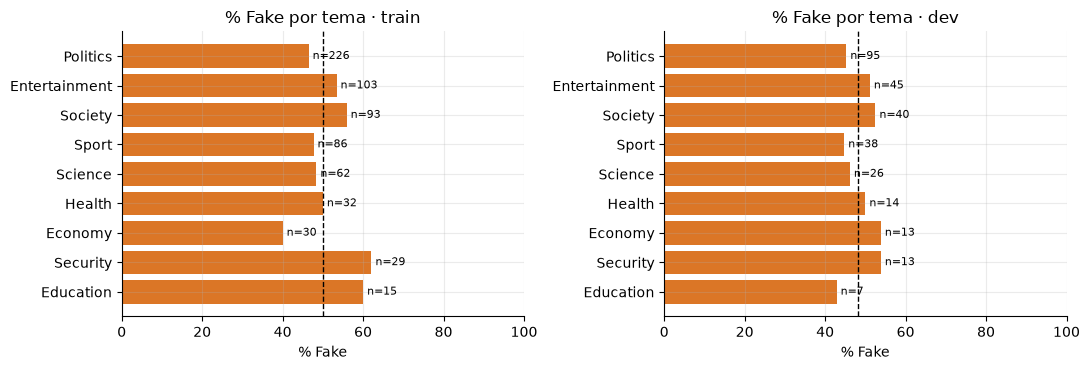

In [5]:
tp = pd.DataFrame({"train": train.Topic.value_counts(), "dev": dev.Topic.value_counts()}).fillna(0).astype(int)
tp["% train"] = (100 * tp.train / tp.train.sum()).round(1)
tp["% dev"] = (100 * tp.dev / tp.dev.sum()).round(1)
for k in ("train", "dev"):
    tp[f"% Fake {k}"] = (100 * S[k].groupby("Topic").label.mean()).round(1)
savetab(tp, "02_temas_train_dev.csv")
display(tp)
tt = test.Topic.value_counts().rename("test (n)").to_frame()
tt["% Fake (no se calcula: test sin etiquetas en el análisis)"] = "—"
display(tt.iloc[:, :1])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
orden = tp.sort_values("train").index
for a, k in zip(ax, ("train", "dev")):
    d = S[k].groupby("Topic").label.agg(["mean", "size"]).loc[orden]
    a.barh(d.index, 100 * d["mean"], color=COL["Fake"], alpha=.85)
    a.axvline(100 * S[k].label.mean(), color="k", ls="--", lw=1)
    for i, (m, n) in enumerate(zip(d["mean"], d["size"])):
        a.text(100 * m + 1, i, f"n={n}", va="center", fontsize=8)
    a.set_title(f"% Fake por tema · {k}"); a.set_xlim(0, 100); a.set_xlabel("% Fake")
fig.tight_layout(); savefig(fig, "02_fake_por_tema_train_dev.png"); plt.show()

**Conclusión e implicación para el diseño**

- Los temas se reparten casi igual en train y dev (Politics ≈ 33 %, Entertainment ≈ 15 %…), y la proporción Fake es cercana al 50 % en todos. Los extremos (Security 62 % / 54 %, Economy 40 % / 54 %, Education 60 % / 43 %) tienen pocos ejemplos y no se repiten entre train y dev, así que parecen ruido.
- Conclusión: **el tema no discrimina**; el problema no es temático y un clasificador no debería apoyarse en él.
- `Topic` **no es comparable** con test: en train/dev son 9 categorías en inglés, en test 7 en español con otro reparto (Covid-19 237, Sociedad 195, Política 107…). No se usará como característica ni para estratificar entre conjuntos.
- **Implicación:** estratificar solo por etiqueta; si se quiere medir robustez por tema, definir una taxonomía común propia (por ejemplo, por palabras clave) en lugar de reutilizar `Topic`.

## 3 · Fuentes y enlaces

Se presenta un informe mostrando la fracción de `fake` news por **dominio** url del `Link`

In [6]:
g = train.groupby("domain").label.agg(n="size", n_fake="sum")
g["frac_fake"] = g.n_fake / g.n
g["pura"] = (g.frac_fake == 0) | (g.frac_fake == 1)
g["clase"] = np.where(g.frac_fake >= .5, "Fake", "True")
n_dom, n_pura = len(g), int(g.pura.sum())
multi = g[g.n >= 2]
print(f"Dominios distintos en train: {n_dom} · 100 % de una sola clase: {n_pura} ({100*n_pura/n_dom:.0f} %)")
print(f"Dominios con ≥2 noticias: {len(multi)} · puros: {int(multi.pura.sum())} ({100*multi.pura.mean():.0f} %)")
print(f"Noticias de train en dominios puros: {100*g[g.pura].n.sum()/g.n.sum():.1f} %")
top = g.sort_values("n", ascending=False).head(12)
savetab(g.sort_values("n", ascending=False), "03_pureza_dominios_train.csv")
display(top[["n", "n_fake", "frac_fake", "pura"]])

# Cobertura de dominios en dev y test.
for k in ("dev", "test"):
    d = S[k]; con_link = d.domain != ""
    en_train = d.domain.isin(g.index)
    dk = set(d.domain[con_link])
    print(f"{k}: dominios distintos={len(dk)} · también en train={len(dk & set(g.index))}"
          f" · noticias con dominio visto en train={100*en_train.mean():.1f} %")
known = dev[dev.domain.isin(g.index)]
pred = (known.domain.map(g.frac_fake) >= .5).astype(int)
print(f"dev: regla 'clase mayoritaria del dominio en train' → acierto {100*(pred == known.label).mean():.1f} % sobre el {100*len(known)/len(dev):.1f} % de dev con dominio conocido")
print("test: Source vacío =", int((test.Source == "").sum()), "· Link vacío =", int((test.Link == "").sum()))
print("Dominios más frecuentes en test:", test.domain.value_counts().head(8).to_dict())

Dominios distintos en train: 109 · 100 % de una sola clase: 105 (96 %)
Dominios con ≥2 noticias: 47 · puros: 43 (91 %)
Noticias de train en dominios puros: 91.6 %


,n,n_fake,frac_fake,pura
domain,,,,
eldizque.com,99,99,1.000000,True
elruinaversal.com,55,55,1.000000,True
elpais.com,53,0,0.000000,True
eluniversal.com.mx,45,1,0.022222,False
excelsior.com.mx,35,0,0.000000,True
haynoticia.es,31,31,1.000000,True
censura0.com,25,25,1.000000,True
forbes.com.mx,21,0,0.000000,True
modonoticia.com,19,19,1.000000,True


dev: dominios distintos=69 · también en train=42 · noticias con dominio visto en train=90.7 %
test: dominios distintos=246 · también en train=31 · noticias con dominio visto en train=42.7 %
dev: regla 'clase mayoritaria del dominio en train' → acierto 98.5 % sobre el 90.7 % de dev con dominio conocido
test: Source vacío = 7 · Link vacío = 3
Dominios más frecuentes en test: {'eluniversal.com.mx': 29, 'elpais.com': 27, 'bbc.com': 27, 'milenio.com': 27, 'facebook.com': 25, 'perma.cc': 23, 'mediterraneodigital.com': 16, 'elfinanciero.com.mx': 15}


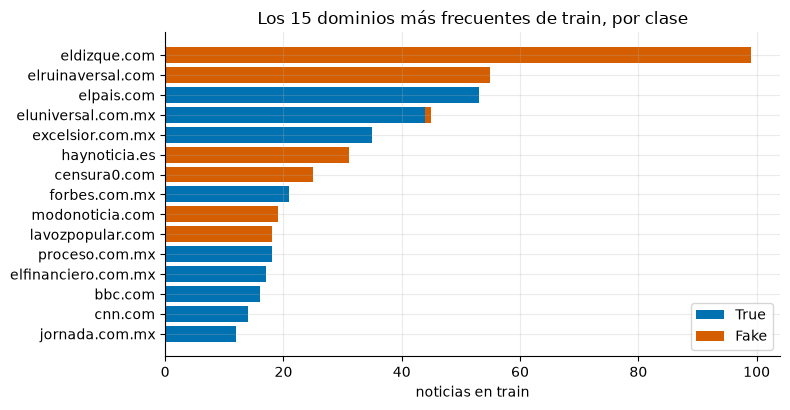

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
t15 = g.sort_values("n", ascending=False).head(15).iloc[::-1]
ax.barh(t15.index, t15.n - t15.n_fake, color=COL["True"], label="True")
ax.barh(t15.index, t15.n_fake, left=t15.n - t15.n_fake, color=COL["Fake"], label="Fake")
ax.set_xlabel("noticias en train"); ax.set_title("Los 15 dominios más frecuentes de train, por clase"); ax.legend()
fig.tight_layout(); savefig(fig, "03_dominios_train_por_clase.png"); plt.show()

**Conclusión e implicación para el diseño**

- Con el dominio registrable (sin `www` ni subdominios) hay 109 dominios en train, de los cuales **105 (96 %) son de una sola clase**; con ≥2 noticias, 43 de 47 (91 %). El 91,6 % de las noticias de train pertenece a dominios puros. (La cifra de 107 sobre 111 que tenías sale con otra normalización del dominio; la conclusión es la misma.)
- En dev, el 90,7 % de las noticias tiene un dominio visto en train y la regla «clase mayoritaria del dominio» acierta el **98,5 %**. Ese acierto no mide ninguna capacidad de detectar falsedad: mide que los sitios satíricos (El Dizque, El Ruinaversal, Hay Noticia, Censura 0…) solo publican Fake y los medios convencionales solo True.
- En test el patrón no se traslada: 246 dominios distintos, solo 31 vistos en train (42,7 % de las noticias). Hay además `Source` y `Link` vacíos.
- **Implicación (regla 1):** `Source` y `Link` solo se usan de forma descriptiva. Un modelo que los vea parecerá excelente en dev y no generalizará (se demuestra en la sección 11). Tampoco se mostrarán dominios ni nombres de medio al LLM ni en los ejemplos recuperados por el RAG.

### Preprocesado compartido 

Antes de medir fugas léxicas, términos o dominios hace falta una versión **limpia** del texto (`clean`). Los patrones viven en `src/eda_utils.py` (`LEAK_PATTERNS`, `build_media_regex`, `clean_text`): URLs, créditos, firmas, agencias, nombres de medio, menciones/hashtags; las cifras se unifican en el token `NUM` porque train/dev traen `*NUMBER*` y test trae cifras reales. Los nombres de medio salen de los `Source` de **train y dev** más una lista manual de medios habituales.

In [8]:
media_re = eu.build_media_regex(pd.concat([train.Source, dev.Source]).unique())
for k, d in S.items():
    d["clean"] = d.input.map(lambda s: eu.clean_text(s, media_re))
    d["clean_body"] = d.body.map(lambda s: eu.clean_text(s, media_re))
print(train.input.iloc[3][:230].replace("\n", " ⏎ "), "\n →", train.clean.iloc[3][:230])

UNAM capacitará a maestros para aprobar prueba Pisa ⏎  ⏎ La máxima casa de estudios y la SEP firmaron cinco convenios para que las facultades de Ciencias y Química, así como el Instituto de Matemáticas de enseñen a los profesores estr 
 → UNAM capacitará a maestros para aprobar prueba Pisa La máxima casa de estudios y la SEP firmaron cinco convenios para que las facultades de Ciencias y Química, así como el Instituto de Matemáticas de enseñen a los profesores estra


## 4 · Longitud

**Pregunta:** ¿cuánto miden titulares y textos por conjunto y clase? ¿Qué porcentaje supera ~400 palabras (límite típico de modelos de embeddings) y ~800 (contexto razonable para un LLM con varios ejemplos recuperados)?

In [9]:
def lens(d):
    return pd.DataFrame({
        "split": d.split, "clase": d.Category if d.split.iloc[0] != "test" else "todas",   
        "titular_palabras": d.Headline.str.split().str.len(), "titular_chars": d.Headline.str.len(),
        "cuerpo_palabras": d.body.str.split().str.len(), "cuerpo_chars": d.body.str.len(),
        "input_palabras": d.input.str.split().str.len()})
L = pd.concat([lens(d) for d in S.values()], ignore_index=True)
L.loc[L.titular_palabras == 0, ["titular_palabras", "titular_chars"]] = np.nan   
cols = ["titular_palabras", "titular_chars", "cuerpo_palabras", "cuerpo_chars"]
desc = L.groupby(["split", "clase"])[cols].agg(["mean", "median", "max"]).round(0).astype("Int64")
savetab(desc, "04_longitudes_por_conjunto_y_clase.csv")
display(desc)

def pct(x, t): return round(100 * (x > t).mean(), 1)
umbral = pd.DataFrame({
    (s, c): {"mediana palabras": L[mask].input_palabras.median(), "% > 400": pct(L[mask].input_palabras, 400),
             "% > 800": pct(L[mask].input_palabras, 800)}
    for s in S for c in (("Fake", "True", "todas") if s != "test" else ("todas",))
    for mask in [(L.split == s) & ((L.clase == c) if c != "todas" else True)]}).T
savetab(umbral, "04_umbrales_longitud.csv")
display(umbral)

titular_palabras            titular_chars             cuerpo_palabras              cuerpo_chars              
                        mean median max          mean median  max            mean median   max         mean median    max
split clase                                                                                                              
dev   Fake                12     12  21            75     73  120             311    270  1191         1849   1613   7240
      True                10     10  28            59     60  151             495    374  2558         3007   2266  15295
test  todas               13     12  28            78     75  173             521    398  4006         3174   2410  25663
train Fake                12     12  23            73     72  131             283    258  1664         1690   1531   9971
      True                10     10  22            63     62  126             450    372  2068         2745   2291  12366

mediana palabras  % > 400  % > 800
train Fake              269.0     21.6      0.6
      True              382.0     47.3     10.9
      todas             314.5     34.5      5.8
dev   Fake              283.5     23.6      1.4
      True              385.0     45.7     11.9
      todas             318.0     35.1      6.9
test  todas             411.0     51.2     17.3

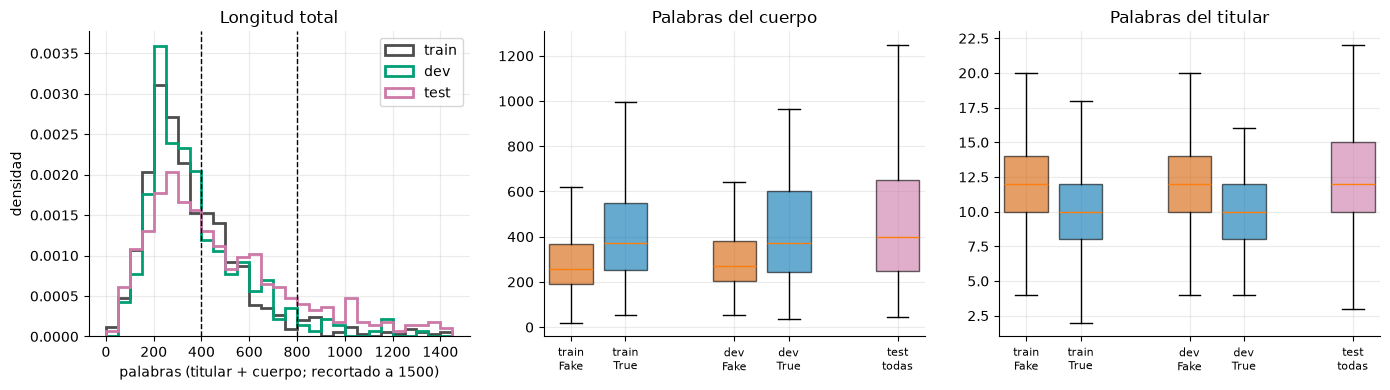

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
bins = np.arange(0, 1500, 50)
for s in S:
    ax[0].hist(L[L.split == s].input_palabras.clip(upper=1499), bins=bins, density=True, histtype="step", lw=2, color=COLS[s], label=s)
for t in (400, 800): ax[0].axvline(t, color="k", ls="--", lw=1)
ax[0].set_xlabel("palabras (titular + cuerpo; recortado a 1500)"); ax[0].set_ylabel("densidad"); ax[0].legend(); ax[0].set_title("Longitud total")

grupos = [("train", "Fake"), ("train", "True"), ("dev", "Fake"), ("dev", "True"), ("test", "todas")]
pos = [0, 1, 3, 4, 6]; lab = [f"{s}\n{c}" for s, c in grupos]; colr = [COL.get(c, COLS["test"]) for _, c in grupos]
for a, col, ttl in ((ax[1], "cuerpo_palabras", "Palabras del cuerpo"), (ax[2], "titular_palabras", "Palabras del titular")):
    data = [L[(L.split == s) & (L.clase == c)][col].dropna() for s, c in grupos]
    bp = a.boxplot(data, positions=pos, widths=.8, patch_artist=True, showfliers=False)
    for patch, cc in zip(bp["boxes"], colr): patch.set_facecolor(cc); patch.set_alpha(.6)
    a.set_xticks(pos); a.set_xticklabels(lab, fontsize=8); a.set_title(ttl)
fig.tight_layout(); savefig(fig, "04_longitudes.png"); plt.show()

In [11]:
# Ventanas de 300 palabras con 50 de solape (ejemplo)
def n_chunks(n, size=300, overlap=50):
    return 1 if n <= size else int(np.ceil((n - overlap) / (size - overlap)))
ch = L.assign(chunks=L.input_palabras.map(n_chunks)).groupby("split").chunks.agg(["mean", "median", "max"]).round(2)
ch["% docs con >1 chunk"] = L.assign(c=L.input_palabras.map(n_chunks)).groupby("split").c.apply(lambda x: round(100 * (x > 1).mean(), 1))
savetab(ch, "04_chunks_300_50.csv")
ch

,mean,median,max,% docs con >1 chunk
split,,,,
dev,1.97,2.0,11,56.4
test,2.43,2.0,16,66.8
train,1.79,2.0,9,52.5


**Conclusión e implicación para el diseño**

- **La longitud es una señal de clase en train/dev:** las Fake son más cortas (mediana de 258-270 palabras de cuerpo frente a 372-374 en True). Es un artefacto de cómo se construyó el corpus y un riesgo si se aprende de forma implícita; los titulares Fake también son más largos (12 frente a 10 palabras). Para test no se desglosa por clase (regla 2).
- **Test es más largo:** mediana de 398 palabras de cuerpo frente a 258-374 en train y media de 521 frente a 378; máximo de 4.006 palabras.
- El 34,5 % de train (35,1 % de dev) supera 400 palabras y solo un 5,8 % (6,9 %) supera 800; en test son el **51,2 %** y el **17,3 %**.
- **Implicación para el chunking:** truncar a 400 palabras perdería la segunda mitad en más de la mitad de test. Para el RAG conviene trocear en ventanas de unas 300 palabras con 50 de solape (media de 2,4 trozos por noticia en test, 66,8 % con más de uno; en train 1,8). Para el LLM como clasificador, pasar el texto completo hasta ~800 palabras y resumir o truncar de forma explícita por encima de eso. Los ejemplos recuperados deben ir truncados a un presupuesto fijo para que el prompt no dependa de la longitud de cada noticia.

## 5 · Titulares vacíos

**Pregunta:** ¿cuántos titulares están vacíos en test, en qué noticias y cómo afecta a un sistema que debe funcionar con solo el texto? 

In [12]:
e = test[test.Headline == ""]; ne = test[test.Headline != ""]
print(f"Test: {len(e)} de {len(test)} titulares vacíos ({100*len(e)/len(test):.1f} %); train: {int((train.Headline=='').sum())}, dev: {int((dev.Headline=='').sum())}")
cmp = pd.DataFrame({
    "con titular": {"n": len(ne), "palabras (mediana)": ne.body.str.split().str.len().median(), "Source vacío": int((ne.Source == "").sum())},
    "sin titular": {"n": len(e), "palabras (mediana)": e.body.str.split().str.len().median(), "Source vacío": int((e.Source == "").sum())}})
display(cmp)
display(pd.crosstab(test.Topic, test.Headline == "").rename(columns={False: "con titular", True: "sin titular"}))
print("Primeras palabras de textos sin titular:")
for s in e.body.head(3): print("  ·", s[:130])

Test: 72 de 572 titulares vacíos (12.6 %); train: 0, dev: 0


,con titular,sin titular
n,500.0,72.0
palabras (mediana),425.5,239.5
Source vacío,3.0,4.0


Headline,con titular,sin titular
Topic,,
Ambiental,3,1
Ciencia,11,2
Covid-19,192,45
Deporte,2,0
Internacional,14,0
Política,90,17
Sociedad,188,7


Primeras palabras de textos sin titular:
  · Se han dado a conocer los datos electorales preliminares de las Personas Privadas de Libertad (PPL), que en Ecuador votan en prime
  · Boooomm MUJERES VACUNADAS DE COVID ESTÁN MOSTRANDO EFECTOS SECUNDARIOS TÍPICOS DE CANCER DE MAMA Los médicos de Intermountain Heal
  · COMUNICADO DEL VICEPRESIDENTE DE FEDERACIÓN AJYPE, Don Antonio Hidalgo Gomez Estimados Amigos y Compañeros, aunque sea un poco tar


In [13]:
# ¿Cuánto importa el titular? TF-IDF palabra sobre texto limpio, entrenado en train y evaluado en dev
def fit_dev(col_tr, col_dev, kind="word", C=10):
    m = eu.make_pipe(kind, C).fit(train[col_tr], train.label)
    p = m.predict(dev[col_dev]); return f1_fake(dev.label, p)
res5 = pd.Series({
    "entrena con titular+cuerpo → dev con titular+cuerpo": fit_dev("clean", "clean"),
    "entrena con titular+cuerpo → dev SOLO cuerpo": fit_dev("clean", "clean_body"),
    "entrena SOLO cuerpo → dev SOLO cuerpo": fit_dev("clean_body", "clean_body")}, name="F1 Fake dev").round(3)
savetab(res5.to_frame(), "05_efecto_titular_dev.csv")
res5.to_frame()

,F1 Fake dev
entrena con titular+cuerpo → dev con titular+cuerpo,0.777
entrena con titular+cuerpo → dev SOLO cuerpo,0.780
entrena SOLO cuerpo → dev SOLO cuerpo,0.783


**Conclusión e implicación para el diseño**

- Test tiene **72 titulares vacíos (12,6 %)**; train y dev, ninguno. Se concentran en Covid-19 (45 de 237) y Política (17 de 107), y sus textos son más cortos (mediana de 240 palabras frente a 426).
- En dev, el titular aporta casi nada a un TF-IDF: F1 Fake 0,780 con titular y cuerpo, 0,783 evaluando solo con el cuerpo y 0,785 entrenando y evaluando solo con el cuerpo. Quitarlo no degrada nada medible.
- **Implicación:** el sistema debe funcionar con **solo el texto**. Se entrena y se evalúa también sin titular y el prompt del LLM trata el titular como campo opcional («Titular: no disponible»), en lugar de rellenarlo con algo inventado. El análisis de estilo del titular (sección 7) es útil como diagnóstico, pero no se puede depender de él.

## 6 · Fugas léxicas

**Pregunta:** ¿aparecen en el `Text` nombres de medios, URLs, firmas o créditos ("Foto:", "Fuente:", "Redacción"…) asociados a la clase? (En test no se mira la etiqueta.)

In [14]:
rows = []
for name, pat in eu.LEAK_PATTERNS.items():
    r = {"patrón": name}
    for k in ("train", "dev", "test"):
        m = S[k].Text.map(lambda t: bool(pat.search(t)))
        r[f"n {k}"] = int(m.sum())
        if k != "test": r[f"% Fake {k}"] = round(100 * S[k].label[m].mean(), 0) if m.sum() else np.nan
    rows.append(r)
# nombre de medio (de Source, train+dev) dentro de Text/Titular, y nombre del propio Source
for etiqueta, f in (("medio (lista) en texto", lambda d: d.input.map(lambda t: bool(media_re.search(t)))),
                    ("su propio Source en texto", lambda d: d.apply(lambda r: bool(r.Source) and r.Source.casefold() in r.input.casefold(), axis=1))):
    r = {"patrón": etiqueta}
    for k in ("train", "dev", "test"):
        m = f(S[k]); r[f"n {k}"] = int(m.sum())
        if k != "test": r[f"% Fake {k}"] = round(100 * S[k].label[m].mean(), 0) if m.sum() else np.nan
    rows.append(r)
leak = pd.DataFrame(rows).set_index("patrón")
savetab(leak, "06_fugas_lexicas.csv")
leak

,n train,% Fake train,n dev,% Fake dev,n test
patrón,,,,,
url,10,40.0,4,25.0,8
credito_foto,6,0.0,2,0.0,0
fuente,0,NaN,0,NaN,2
redaccion,3,33.0,3,67.0,6
con_informacion_de,5,40.0,4,50.0,3
via,0,NaN,0,NaN,1
lee_tambien,3,67.0,1,0.0,2
dateline,70,87.0,37,95.0,3
agencia,9,0.0,3,0.0,15


In [15]:
# Ejemplos de contexto y efecto de la limpieza
for nombre in ("credito_foto", "via", "dateline"):
    pat = eu.LEAK_PATTERNS[nombre]
    ej = [m.group(0)[:70] for t in pd.concat([train.Text, test.Text]) for m in [pat.search(t)] if m][:4]
    print(f"{nombre:13s}", ej)
quitado = lambda d: (1 - d.clean.str.len() / d.input.str.len()).groupby(d.Category).mean()
print("\nFracción media de caracteres eliminada por la limpieza:")
print(pd.concat([quitado(train).rename("train"), quitado(dev).rename("dev")], axis=1).round(3))
print("Patrones propuestos para limpiar:", ", ".join(eu.LEAK_PATTERNS), "+ nombres de medio + cifras → NUM")

credito_foto  ["Foto: Acapulco 5K Internacional 'Ronald Johnson') El deporte mexic", 'Foto: Marco Peláez La comisión especial encargada de investigar a ', 'imagen: que es difícil que conecte con las audiencias', 'Foto: @EstadioAzteca']
via           ['vía: la']
dateline      ['España.- ', 'México.- ', 'México.- ', 'México.- ']

Fracción media de caracteres eliminada por la limpieza:
          train    dev
Category              
Fake      0.016  0.015
True      0.021  0.020
Patrones propuestos para limpiar: url, credito_foto, fuente, redaccion, con_informacion_de, via, lee_tambien, dateline, agencia, mencion_hashtag + nombres de medio + cifras → NUM


**Conclusión e implicación para el diseño**

- En `Text` no hay firmas de medio explícitas del tipo «Fuente:» (0 en train/dev), y los créditos («Foto:», 6 casos), agencias (AFP, EFE… 9 casos, 0 % Fake) y «Redacción» son raros. Los números son pequeños, pero todos apuntan a True y son rasgos de prensa convencional.
- **Fugas más relevantes:**
  - *Dateline* tipo «México.- » o «España.- »: 70 casos en train con **87 % Fake** y 37 en dev con **95 % Fake**; solo aparece 3 veces en test. Es un rasgo de las webs que imitan estilo de agencia, no de la falsedad.
  - El propio nombre del medio dentro del texto: 49 casos en train con un **2 % Fake** (10 % en dev).
  - URLs, menciones y hashtags: pocos casos, sin patrón estable. El marcador `*URL*` solo está en 10 textos de train.
- La limpieza elimina solo el ~2 % de los caracteres (1,6 % en Fake y 2,1 % en True), así que no destruye contenido.
- **Patrones a limpiar antes de modelar** (en `eda_utils.LEAK_PATTERNS`): URLs y `*URL*`, créditos de foto o imagen, «Fuente:», «Redacción», «Con información de…», «Vía: @…», «Lee también…/Síguenos…», dateline «Ciudad.- », agencias, menciones y hashtags, nombres de medio (`Source` de train+dev más una lista de medios habituales) y cifras → `NUM`.
- Falta el control opuesto: la limpieza es heurística y no garantiza que no queden otras marcas de medio; hay que revisar los términos más discriminativos del modelo final.

## 7 · Estilo

**Pregunta:** ¿hay señales estilísticas (titular largo, mayúsculas, exclamaciones, interrogaciones, comillas, cifras, emojis) que distingan Fake de True en train? ¿Se mantienen en dev?

In [16]:
def style_df(d):
    f = pd.DataFrame([eu.style_features(h, b) for h, b in zip(d.Headline, d.body)], index=d.index)
    f.loc[d.Headline == "", [c for c in f if c.startswith("titular")]] = np.nan
    return f
F = {k: style_df(d) for k, d in S.items()}
medias = pd.concat({(k, c): F[k][S[k].Category == c].mean() for k in ("train", "dev") for c in ("Fake", "True")}, axis=1)
medias[("test", "todas")] = F["test"].mean()
savetab(medias, "07_estilo_medias.csv")
display(medias.round(3))

def auc_feature(k, c):
    x = F[k][c]; ok = x.notna()
    return roc_auc_score(S[k].label[ok], x[ok])
au = pd.DataFrame({"AUC train": {c: auc_feature("train", c) for c in F["train"]},
                   "AUC dev": {c: auc_feature("dev", c) for c in F["train"]}}).round(3)
savetab(au, "07_estilo_auc_por_variable.csv")
display(au)

train             dev           test
                             Fake    True    Fake   True   todas
titular_palabras           12.260  10.485  12.407  9.954  12.804
titular_mayus_frac          0.234   0.100   0.284  0.098   0.083
titular_todo_mayus          0.154   0.015   0.214  0.007   0.026
cuerpo_mayus_frac           0.039   0.054   0.040  0.053   0.039
exclamaciones_100p          0.205   0.050   0.048  0.059   0.172
interrogaciones_100p        0.234   0.084   0.147  0.107   0.341
titular_exclama_interroga   0.038   0.053   0.057  0.040   0.078
comillas_100p               2.068   1.902   1.946  1.886   1.899
cifras_100p                 0.693   1.704   0.876  1.574   1.834
emojis                      0.000   0.000   0.000  0.000   0.177

,AUC train,AUC dev
titular_palabras,0.658,0.713
titular_mayus_frac,0.574,0.601
titular_todo_mayus,0.570,0.604
cuerpo_mayus_frac,0.288,0.298
exclamaciones_100p,0.529,0.476
interrogaciones_100p,0.523,0.516
titular_exclama_interroga,0.493,0.509
comillas_100p,0.549,0.534
cifras_100p,0.277,0.299
emojis,0.500,0.500


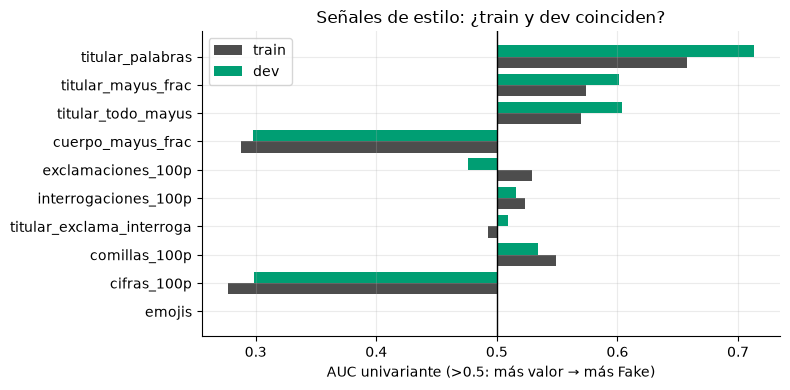

Regresión logística solo con estilo · train → dev: F1 Fake = 0.704, AUC = 0.780


In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(au))
ax.barh(y + .2, au["AUC train"] - .5, .4, left=.5, color=COLS["train"], label="train")
ax.barh(y - .2, au["AUC dev"] - .5, .4, left=.5, color=COLS["dev"], label="dev")
ax.axvline(.5, color="k", lw=1); ax.set_yticks(y); ax.set_yticklabels(au.index); ax.invert_yaxis()
ax.set_xlabel("AUC univariante (>0.5: más valor → más Fake)"); ax.set_title("Señales de estilo: ¿train y dev coinciden?"); ax.legend()
fig.tight_layout(); savefig(fig, "07_estilo_auc_train_dev.png"); plt.show()

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
sty = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)).fit(F["train"], train.label)
print(f"Regresión logística solo con estilo · train → dev: F1 Fake = {f1_fake(dev.label, sty.predict(F['dev'])):.3f}, AUC = {roc_auc_score(dev.label, sty.predict_proba(F['dev'])[:,1]):.3f}")

**Conclusión e implicación para el diseño**

- **Señales fuertes y estables entre train y dev:**
  - Titular en MAYÚSCULAS: 15 % de los Fake frente a 1,5 % de los True en train, y 21 % frente a 0,7 % en dev (AUC 0,57-0,60).
  - Pocas cifras en el cuerpo: AUC 0,28 en train y 0,30 en dev, es decir, los True llevan más cifras.
  - Menos mayúsculas en el cuerpo (AUC 0,29 / 0,30) y titular más largo (AUC 0,66 / 0,71).
- **Señales que no se mantienen:** exclamaciones (AUC 0,53 en train, 0,48 en dev), interrogaciones, comillas y signos en el titular están cerca de 0,5.
- Un modelo logístico solo con estas 10 variables da F1 Fake **0,704** y AUC 0,78 en dev, sorprendentemente alto para tan poca información.
- **Advertencia frente al cambio de dominio:** en test casi no hay titulares en mayúsculas (2,6 % frente a 8,5 % en train) ni emojis en train/dev (0) pero sí en test (0,18 por noticia). Estas señales, que funcionan en dev, probablemente se debiliten en test.
- **Implicación:** el estilo es un riesgo de atajo, no una ventaja. No se añadirá como característica del modelo final; se usará como diagnóstico y como contraste («¿el LLM razona más allá del estilo del texto?»). 

## 8 · Términos discriminativos

**Pregunta:** tras limpiar medios y URLs, ¿qué palabras separan Fake de True en train (log-odds con suavizado y z-score) y siguen funcionando en dev?

In [18]:
cv = CountVectorizer(min_df=5, binary=True, strip_accents="unicode", token_pattern=r"(?u)\b[^\W\d_]{3,}\b", lowercase=True)
Xtr = cv.fit_transform(train.clean)
vocab = np.array(cv.get_feature_names_out())
keep = vocab != "num"
y = train.label.values
lo_tr, z_tr = eu.log_odds_z(Xtr[y == 1], Xtr[y == 0])
Xdv = cv.transform(dev.clean); yd = dev.label.values
lo_dv, z_dv = eu.log_odds_z(Xdv[yd == 1], Xdv[yd == 0])
df_dv = np.asarray(Xdv.sum(axis=0)).ravel(); df_tr = np.asarray(Xtr.sum(axis=0)).ravel()
T = pd.DataFrame({"término": vocab, "df_train": df_tr, "z_train": z_tr, "z_dev": z_dv, "df_dev": df_dv})[keep]
top_f = T.sort_values("z_train", ascending=False).head(25)
top_t = T.sort_values("z_train").head(25)
savetab(pd.concat([top_f.assign(clase="Fake"), top_t.assign(clase="True")]).round(2), "08_terminos_discriminativos.csv", index=False)
display(pd.concat([top_f.reset_index(drop=True).add_suffix(" (Fake)"), top_t.reset_index(drop=True).add_suffix(" (True)")], axis=1)
        [["término (Fake)", "z_train (Fake)", "z_dev (Fake)", "término (True)", "z_train (True)", "z_dev (True)"]].round(1).head(20))

,término (Fake),z_train (Fake),z_dev (Fake),término (True),z_train (True),z_dev (True)
0,todo,5.0,2.4,cinco,-3.9,-2.7
1,esto,4.9,1.5,instituto,-3.7,-1.4
2,puntualizo,4.8,3.1,desarrollo,-3.6,-1.3
3,conferencia,4.7,1.9,domingo,-3.5,-1.9
4,nadie,4.6,1.6,tres,-3.5,-1.8
5,pues,4.5,1.4,mil,-3.4,0.2
6,gente,4.5,3.0,federal,-3.4,0.3
7,sera,4.4,2.5,indico,-3.4,-2.0
8,pero,4.3,2.7,proceso,-3.3,-1.7
9,nos,3.9,2.8,casos,-3.3,-0.6


Términos comparables: 2238 · Spearman z_train vs z_dev = 0.40
Términos con |z_train| ≥ 2.5: 128 · mismo signo en dev: 94 %
Suma de log-odds de train → dev: AUC = 0.862


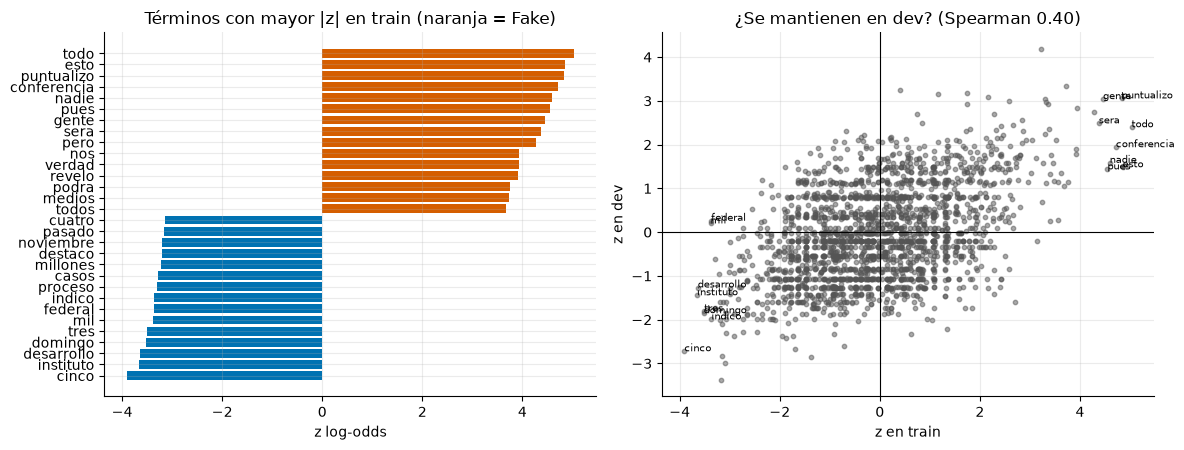

In [19]:
from scipy.stats import spearmanr
ok = T[(T.df_train >= 8) & (T.df_dev >= 3)]
rho = spearmanr(ok.z_train, ok.z_dev)[0]
fuertes = ok[ok.z_train.abs() >= 2.5]
acuerdo = (np.sign(fuertes.z_train) == np.sign(fuertes.z_dev)).mean()
print(f"Términos comparables: {len(ok)} · Spearman z_train vs z_dev = {rho:.2f}")
print(f"Términos con |z_train| ≥ 2.5: {len(fuertes)} · mismo signo en dev: {100*acuerdo:.0f} %")

# Suma de log-odds de train sobre los términos de cada noticia de dev
w = np.where(keep, lo_tr, 0.0)
score = Xdv @ w
print(f"Suma de log-odds de train → dev: AUC = {roc_auc_score(yd, score):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
comb = pd.concat([top_t.head(15), top_f.head(15)]).sort_values("z_train")
ax[0].barh(comb["término"], comb.z_train, color=[COL["Fake"] if z > 0 else COL["True"] for z in comb.z_train])
ax[0].set_title("Términos con mayor |z| en train (naranja = Fake)"); ax[0].set_xlabel("z log-odds")
ax[1].scatter(ok.z_train, ok.z_dev, s=10, alpha=.5, color="#555")
ax[1].axhline(0, color="k", lw=.8); ax[1].axvline(0, color="k", lw=.8)
for _, r in pd.concat([top_f.head(8), top_t.head(8)]).iterrows():
    ax[1].annotate(r["término"], (r.z_train, r.z_dev), fontsize=7)
ax[1].set_xlabel("z en train"); ax[1].set_ylabel("z en dev"); ax[1].set_title(f"¿Se mantienen en dev? (Spearman {rho:.2f})")
fig.tight_layout(); savefig(fig, "08_terminos_discriminativos.png"); plt.show()

**Conclusión e implicación para el diseño**

- Los términos con mayor z en Fake son **palabras funcionales y de discurso directo** («todo», «esto», «nadie», «pues», «pero», «nos», «verdad», «puntualizó»), más cercanas a un registro oral y de opinión. Los de True son **cifras escritas con letras y fechas** («cinco», «tres», «mil», «millones», «domingo», «noviembre», «abril») y vocabulario institucional («instituto», «federal», «coalición»).
- Tras limpiar medios y URLs, **se mantienen en dev**: de los 128 términos con |z| ≥ 2,5 en train, el **94 %** tiene el mismo signo en dev; sumar los log-odds de train da AUC **0,863** en dev. La correlación global es moderada (Spearman 0,40).
- Esto confirma que gran parte de la señal léxica es **estilística y de registro**, y no de contenido factual. Los términos propios de la política mexicana de 2018 aparecen sobre todo como «de train» en el análisis adversarial de la sección 9.
- **Implicación:** un TF-IDF funcionará bien en dev por razones que probablemente no se trasladen a otros países y a COVID. Para el RAG, la recuperación por similitud léxica favorecerá ejemplos del mismo registro, no del mismo hecho. El LLM debería comprobar afirmaciones, no registro.

## 9 · Cambio de dominio train → test

**Pregunta:** ¿cuánto se desplaza el test respecto a train/dev? Solo con texto, sin etiquetas: términos de COVID, palabras fuera de vocabulario y un clasificador adversarial (train+dev frente a test).

In [20]:
cov = pd.DataFrame({k: {
    "% noticias con algún término COVID": round(100 * d.input.map(lambda t: bool(eu.COVID_RE.search(t))).mean(), 1),
    "términos COVID por 1000 palabras": round(1000 * d.input.map(lambda t: len(eu.COVID_RE.findall(t))).sum() / d.input.str.split().str.len().sum(), 2)}
    for k, d in S.items()})
display(cov)
print("Test por tema — % con algún término COVID:")
print(test.groupby("Topic").input.apply(lambda s: round(100 * s.map(lambda t: bool(eu.COVID_RE.search(t))).mean(), 0)).to_dict())

# Palabras fuera del vocabulario de train
rng = np.random.RandomState(SEED); idx = rng.permutation(len(train)); cut = int(.8 * len(train))
def oov(vocab, texts):
    tk = [w for t in texts for w in eu.tokens(t)]
    tipos = set(tk)
    return round(100 * np.mean([w not in vocab for w in tk]), 2), round(100 * np.mean([w not in vocab for w in tipos]), 2)
v_full = {w for t in train.clean for w in eu.tokens(t)}
v_80 = {w for t in train.clean.iloc[idx[:cut]] for w in eu.tokens(t)}
oov_df = pd.DataFrame({
    "control: 20 % de train vs 80 %": oov(v_80, train.clean.iloc[idx[cut:]]),
    "dev vs train": oov(v_full, dev.clean),
    "test vs train": oov(v_full, test.clean)}, index=["% tokens OOV", "% tipos OOV"]).T
savetab(pd.concat([cov.T, oov_df], axis=1), "09_covid_y_oov.csv")
display(oov_df)

,train,dev,test
% noticias con algún término COVID,3.30,4.10,59.60
términos COVID por 1000 palabras,0.18,0.22,11.14


Test por tema — % con algún término COVID:
{'Ambiental': 50.0, 'Ciencia': 54.0, 'Covid-19': 96.0, 'Deporte': 0.0, 'Internacional': 50.0, 'Política': 36.0, 'Sociedad': 30.0}


,% tokens OOV,% tipos OOV
control: 20 % de train vs 80 %,7.82,33.07
dev vs train,6.89,37.15
test vs train,8.61,50.50


In [21]:
def adv_auc(textos_a, textos_b, ngram=(1, 2)):
    X = pd.concat([textos_a, textos_b], ignore_index=True)
    y = np.r_[np.zeros(len(textos_a)), np.ones(len(textos_b))]
    pipe = eu.make_pipe("word", 1.0); pipe.set_params(tfidfvectorizer__ngram_range=ngram)
    sc = cross_val_predict(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="decision_function")
    return roc_auc_score(y, sc)

trdv = pd.concat([train, dev], ignore_index=True)
sin_cov = lambda s: s.map(lambda t: eu.COVID_RE.sub(" ", t))
adv = pd.Series({
    "control: train vs dev (texto limpio)": adv_auc(train.clean, dev.clean),
    "train+dev vs test · texto sin limpiar (con *NUMBER*/URL)": adv_auc(trdv.input, test.input),
    "train+dev vs test · texto limpio": adv_auc(trdv.clean, test.clean),
    "train+dev vs test · limpio y sin términos COVID": adv_auc(sin_cov(trdv.clean), sin_cov(test.clean)),
}, name="AUC adversarial (5-fold)").round(3)
savetab(adv.to_frame(), "09_adversarial_auc.csv")
display(adv.to_frame())

pipe = eu.make_pipe("word", 1.0).fit(pd.concat([sin_cov(trdv.clean), sin_cov(test.clean)]), np.r_[np.zeros(len(trdv)), np.ones(len(test))])
names = np.array(pipe[0].get_feature_names_out()); coef = pipe[1].coef_.ravel()
print("Términos más 'de test' (sin COVID):", list(names[np.argsort(-coef)[:15]]))
print("Términos más 'de train/dev':      ", list(names[np.argsort(coef)[:15]]))

,AUC adversarial (5-fold)
control: train vs dev (texto limpio),0.487
train+dev vs test · texto sin limpiar (con *NUMBER*/URL),0.978
train+dev vs test · texto limpio,0.931
train+dev vs test · limpio y sin términos COVID,0.914


Términos más 'de test' (sin COVID): ['virus', 'as', 'salud', 'personas', 'num', 'el virus', 'casos', 'de salud', 'el num', 'noticia', 'las as', 'paises', 'la num', 'dosis', 'contra']
Términos más 'de train/dev':       ['mexico', 'de mexico', 'pena', 'nieto', 'pena nieto', 'pri', 'mexicano', 'mexicanos', 'amlo', 'candidato', 'enrique', 'su', 'obrador', 'lopez obrador', 'mexicana']


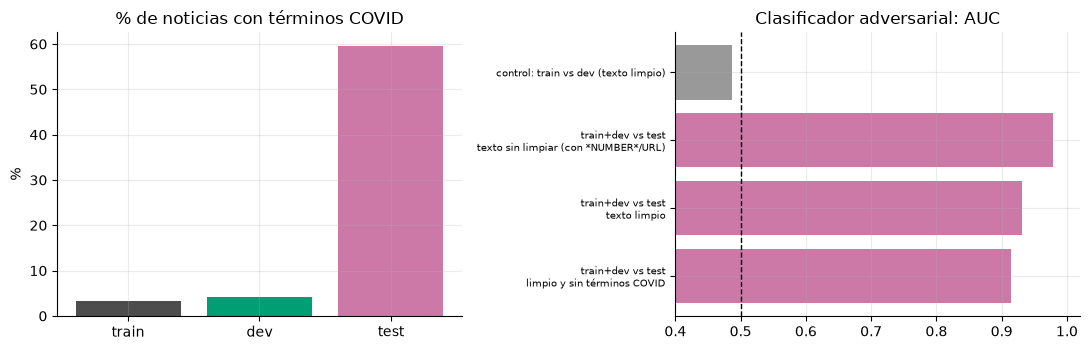

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(cov.columns, cov.iloc[0], color=[COLS[k] for k in cov.columns]); ax[0].set_title("% de noticias con términos COVID"); ax[0].set_ylabel("%")
ax[1].barh(adv.index[::-1], adv.values[::-1], color=["#999", "#CC79A7", "#CC79A7", "#CC79A7"][::-1]); ax[1].axvline(.5, color="k", ls="--", lw=1)
ax[1].set_xlim(.4, 1.02); ax[1].set_yticks(range(len(adv))); ax[1].set_yticklabels([s.replace(" · ", "\n") for s in adv.index[::-1]], fontsize=7); ax[1].set_title("Clasificador adversarial: AUC")
fig.tight_layout(); savefig(fig, "09_cambio_de_dominio.png"); plt.show()

**Conclusión e implicación para el diseño**

- **COVID:** el 3,3 % de las noticias de train y el 4,1 % de dev contienen términos COVID (0,18 y 0,22 por 1.000 palabras) frente al **59,6 %** de test (11,1 por 1.000). Incluso fuera del tema «Covid-19» el 30-36 % de Sociedad y Política los menciona.
- **Vocabulario:** el 8,6 % de los tokens de test no está en el vocabulario de train (6,9 % en dev; control interno del 20 % retenido de train: 7,8 %), y el **50,5 % de los tipos** (37,2 % en dev). El desplazamiento léxico es mucho mayor en tipos que en tokens: las palabras nuevas son raras.
- **Clasificador adversarial:** AUC **0,49** entre train y dev (indistinguibles) frente a **0,93** entre train+dev y test con texto limpio (0,98 sin limpiar, por los marcadores `*NUMBER*`). Sin términos COVID sigue en **0,91**: el desplazamiento no se reduce a la pandemia. Los términos más «de train» son México y su política de 2018 («Peña Nieto», «AMLO», «PRI»).
- **Implicación:** dev **no es representativo** de test; un buen resultado en dev (como el 0,78-0,80 de los TF-IDF) no predice el de test. Toda decisión debe tomarse con dev sabiendo que sobreestima. Hay que preferir métodos que dependan menos del léxico de train (LLM, embeddings multilingües, evidencias externas), incluir en la validación una partición sintética de «cambio de dominio», y vigilar la calibración y el umbral de decisión, que son lo primero que se rompe.

## 10 · Pares true/fake por evento

**Pregunta:** ¿hay noticias casi idénticas de clase contraria (la versión falsa y la verdadera de un mismo evento)? ¿Con qué frecuencia? Esto puede condicionar cómo se particiona la validación y qué ejemplos se recuperan en el RAG.

In [23]:
tf = TfidfVectorizer(min_df=2, sublinear_tf=True, strip_accents="unicode", token_pattern=r"(?u)\b[^\W\d_]{3,}\b")
Xt = tf.fit_transform(train.clean)
sim = (Xt @ Xt.T).toarray(); np.fill_diagonal(sim, 0)
yv = train.label.values
opp = yv[:, None] != yv[None, :]
max_opp = np.where(opp, sim, 0).max(axis=1)
max_same = np.where(~opp, sim, 0).max(axis=1)
nn = sim.argmax(axis=1)
umb = [.3, .4, .5, .6, .7]
tab10 = pd.DataFrame({
    "% con vecino de la clase contraria ≥ umbral": [round(100 * (max_opp >= t).mean(), 1) for t in umb],
    "% con vecino de la misma clase ≥ umbral": [round(100 * (max_same >= t).mean(), 1) for t in umb],
    "% cuyo vecino más cercano es de clase contraria (y ≥ umbral)": [round(100 * ((sim.max(axis=1) >= t) & (yv[nn] != yv)).mean(), 1) for t in umb]},
    index=pd.Index(umb, name="similitud coseno"))
savetab(tab10, "10_vecinos_train.csv"); display(tab10)

pares = np.dstack(np.unravel_index(np.argsort(-np.where(opp, sim, 0), axis=None), sim.shape))[0]
vistos, mostrados = set(), 0
for i, j in pares:
    if i < j and (i, j) not in vistos:
        vistos.add((i, j)); mostrados += 1
        print(f"sim={sim[i, j]:.2f}\n  [{train.Category[i]}] {train.Headline[i][:110]}\n  [{train.Category[j]}] {train.Headline[j][:110]}")
        if mostrados == 3: break

,% con vecino de la clase contraria ≥ umbral,% con vecino de la misma clase ≥ umbral,% cuyo vecino más cercano es de clase contraria (y ≥ umbral)
similitud coseno,,,
0.3,3.3,2.7,3.3
0.4,0.0,0.6,0.0
0.5,0.0,0.3,0.0
0.6,0.0,0.0,0.0
0.7,0.0,0.0,0.0


sim=0.34
  [Fake] MILEY CYRUS ESTÁ EMBARAZADA
  [True] Con foto, Miley Cyrus responde si está embarazada
sim=0.34
  [Fake] Terminando la campaña de los Patriotas, Tom Brady se irá a Miami
  [True] Brady no entrena con los Patriotas por lesión en la mano
sim=0.33
  [Fake] El FBI revela cómo logró desencriptar el iPhone de un terrorista sin la ayuda de Apple
  [True] ¿Cómo logró el FBI desbloquear el iPhone del atacante de San Bernardino y de paso frustrar a Apple?


In [24]:
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix
UMBRAL_GRUPO = .3
n_g, grp = connected_components(csr_matrix(sim >= UMBRAL_GRUPO), directed=False)
tam = pd.Series(grp).value_counts()
print(f"Grupos (componentes conexas con sim ≥ {UMBRAL_GRUPO}): {n_g} · tamaño máx = {tam.max()} · grupos con >1 noticia = {(tam > 1).sum()} · noticias en grupos >1 = {int(tam[tam > 1].sum())}")
savetab(pd.DataFrame({"Id": train.Id, "grupo": grp}), "10_train_grupos.csv", index=False)
train["grupo"] = grp

# ¿Cuánto infla la validación ignorar los grupos? 
def cv_f1(splitter, **kw):
    p = cross_val_predict(eu.make_pipe("word", 10), train.clean, train.label, cv=splitter, **kw)
    return f1_fake(train.label, p)
print(f"CV F1 Fake en train · StratifiedKFold (filas independientes): {cv_f1(StratifiedKFold(5, shuffle=True, random_state=SEED)):.3f}")
print(f"CV F1 Fake en train · GroupKFold (por grupo de evento):       {cv_f1(GroupKFold(5), groups=grp):.3f}")

# Fuga entre conjuntos: vecinos de dev y de test dentro de train
Xd, Xte = tf.transform(dev.clean), tf.transform(test.clean)
sd, ste = (Xd @ Xt.T).toarray(), (Xte @ Xt.T).toarray()
nd = sd.argmax(axis=1)
filas = []
for t in (.4, .5, .6):
    m = sd.max(axis=1) >= t
    filas.append({"umbral": t, "% dev con vecino en train": round(100 * m.mean(), 1),
                  "% de esos con misma clase": round(100 * (yv[nd][m] == dev.label.values[m]).mean(), 0) if m.any() else np.nan,
                  "% test con vecino en train (sin etiquetas)": round(100 * (ste.max(axis=1) >= t).mean(), 1)})
vec_dt = pd.DataFrame(filas).set_index("umbral"); savetab(vec_dt, "10_vecinos_dev_test_en_train.csv"); display(vec_dt)

Grupos (componentes conexas con sim ≥ 0.3): 656 · tamaño máx = 2 · grupos con >1 noticia = 20 · noticias en grupos >1 = 40
CV F1 Fake en train · StratifiedKFold (filas independientes): 0.834
CV F1 Fake en train · GroupKFold (por grupo de evento):       0.840


,% dev con vecino en train,% de esos con misma clase,% test con vecino en train (sin etiquetas)
umbral,,,
0.4,2.4,57.0,0.7
0.5,2.1,67.0,0.7
0.6,0.7,100.0,0.7


**Conclusión e implicación para el diseño**

- **No hay casi duplicados por evento dentro de train**: la similitud coseno máxima entre una noticia y otra de clase contraria es ≈ 0,34, y ningún par de clase contraria llega a 0,4. Con el umbral 0,3, un 3,3 % de las noticias tiene un vecino de clase contraria; los pares que aparecen sí son del mismo evento (Miley Cyrus, Tom Brady, FBI/iPhone), pero con redacción muy distinta.
- Con ese umbral hay 20 grupos de 2 noticias. La validación cruzada **no se infla** por ignorarlos (F1 Fake 0,834 con `StratifiedKFold` y 0,840 con `GroupKFold`), y solo el 2 % de dev tiene un vecino ≥ 0,4 en train (mismo evento y misma clase en el 57 %); en test, el 0,7 %.
- La hipótesis de que había pares true/fake muy parecidos y fugas de eventos no se cumple de forma lexical. Puede haberlos de forma semántica (misma noticia, palabras distintas): el TF-IDF no lo mide; habría que repetirlo con embeddings
- **Implicación:** Usaremos `GroupKFold` con los grupos guardados en `results/eda/10_train_grupos.csv` como precaución, pero no es un factor crítico. Para el RAG, los vecinos léxicos de otra clase son escasos: recuperar ejemplos etiquetados no dará «la versión verdadera de esta noticia falsa», sino textos de estilo parecido.

## 11 · Prueba de control: dominio frente a texto limpio

**Pregunta:** ¿qué rendimiento da un modelo que solo ve el dominio del `Link` (prohibido como entrada en el sistema final) frente a TF-IDF de texto limpio? Debe rendir bien en dev y hundirse en test.

*Protocolo:* los hiperparámetros (C) se eligen con `GroupKFold` sobre train (grupos de la sección 10); dev se evalúa con el modelo entrenado en train; test, con el entrenado en train+dev y el mismo C. Esta celda es de uso informativo

In [ ]:
Cs = [0.1, 1, 10, 100]
def elegir_C(kind, col):
    mejor = {}
    for C in Cs:
        p = cross_val_predict(eu.make_pipe(kind, C), train[col], train.label, cv=GroupKFold(5), groups=train.grupo)
        mejor[C] = f1_fake(train.label, p)
    return max(mejor, key=mejor.get), mejor

trdv = pd.concat([train, dev], ignore_index=True)
modelos = {
    "(a) solo dominio del Link": ("domain", "domain"),
    "(b1) TF-IDF palabras 1-2, texto limpio": ("word", "clean"),
    "(b2) TF-IDF caracteres 2-5, texto limpio": ("char", "clean"),
    "(ref) TF-IDF caracteres 2-5, full_text sin limpiar": ("char", "full_text"),
}
filas = []
for nombre, (kind, col) in modelos.items():
    C, _ = elegir_C(kind, col)
    m_dev = eu.make_pipe(kind, C).fit(train[col], train.label)
    p_dev = m_dev.predict(dev[col])
    m_te = eu.make_pipe(kind, C).fit(trdv[col], trdv.label)
    p_te = m_te.predict(test[col]); s_te = m_te.decision_function(test[col])
    filas.append({"modelo": nombre, "C": C,
                  "F1 Fake dev": f1_fake(dev.label, p_dev), "AUC dev": roc_auc_score(dev.label, m_dev.decision_function(dev[col])),
                  "F1 Fake test": f1_fake(test.label, p_te), "P test": precision_score(test.label, p_te, zero_division=0),
                  "R test": recall_score(test.label, p_te, zero_division=0), "AUC test": roc_auc_score(test.label, s_te),
                  "% pred. Fake en test": 100 * p_te.mean()})
abl = pd.DataFrame(filas).set_index("modelo").round(3)
abl["Δ F1 (test − dev)"] = (abl["F1 Fake test"] - abl["F1 Fake dev"]).round(3)
savetab(abl, "11_prueba_dominio_vs_texto.csv")
display(abl)
print("Referencia: predecir todo Fake en un conjunto balanceado da F1 = 0.667; objetivo de la tarea: 0.76")

,C,F1 Fake dev,AUC dev,F1 Fake test,P test,R test,AUC test,% pred. Fake en test,Δ F1 (test − dev)
modelo,,,,,,,,,
(a) solo dominio del Link,1,0.924,0.992,0.388,0.933,0.245,0.841,13.112,-0.536
"(b1) TF-IDF palabras 1-2, texto limpio",10,0.777,0.885,0.627,0.850,0.497,0.797,29.196,-0.150
"(b2) TF-IDF caracteres 2-5, texto limpio",10,0.800,0.881,0.644,0.842,0.521,0.814,30.944,-0.156
"(ref) TF-IDF caracteres 2-5, full_text sin limpiar",10,0.799,0.880,0.728,0.791,0.675,0.813,42.657,-0.071


Referencia: predecir todo Fake en un conjunto balanceado da F1 = 0.667; objetivo de la tarea: 0.76


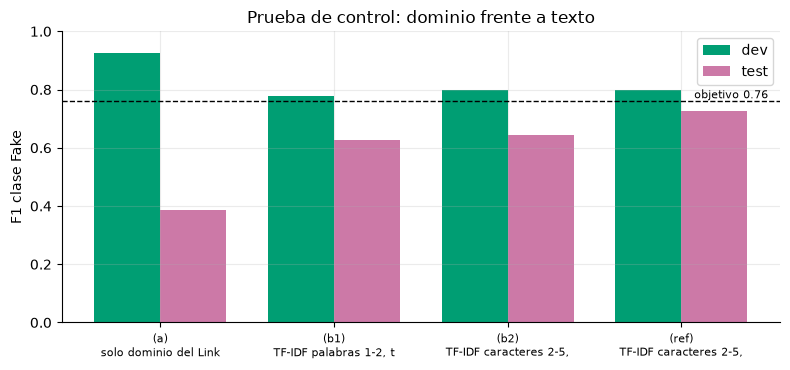

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(abl)); w = .38
ax.bar(x - w/2, abl["F1 Fake dev"], w, color=COLS["dev"], label="dev")
ax.bar(x + w/2, abl["F1 Fake test"], w, color=COLS["test"], label="test")
ax.axhline(.76, color="k", ls="--", lw=1); ax.text(len(abl) - .5, .77, "objetivo 0.76", ha="right", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([s.split(" ", 1)[0] + "\n" + s.split(" ", 1)[1][:22] for s in abl.index], fontsize=8)
ax.set_ylabel("F1 clase Fake"); ax.set_ylim(0, 1); ax.legend(); ax.set_title("Prueba de control: dominio frente a texto")
fig.tight_layout(); savefig(fig, "11_ablacion_f1.png"); plt.show()

**Conclusión e implicación para el diseño**

- **(a) Solo dominio:** F1 Fake **0,924** en dev (AUC 0,99) y **0,388** en test (AUC 0,84), una caída de 0,54. En test acierta el 93 % de lo que marca como Fake (precisión 0,93), pero apenas marca el 13 % de las noticias como Fake (recall 0,25), porque la mayoría de sus dominios no se vieron en train.

- **(b) TF-IDF de texto limpio:** 0,777 (palabras) y 0,800 (caracteres) en dev frente a **0,627 y 0,644** en test: cae unos 0,15. Ningún baseline llega al 0,76 en test.
- El resultado confirma la regla 1: un modelo con dominio parece mejor que cualquiera en dev y se hunde en test.

- **Sorpresa a investigar:** el TF-IDF de caracteres sobre `full_text` **sin limpiar** obtiene 0,728 en test, más que el limpio (0,644), con AUC casi idéntico (0,813 frente a 0,814). El ranking es igual; la diferencia está en cuántas noticias se etiquetan como Fake (43 % frente a 31 % en test). Es decir, el modelo limpio **detecta en menor medida Fake bajo cambio de dominio** (recall 0,52, precisión 0,84) y el problema parece de **umbral y calibración**, no de capacidad. Estas cifras se usan solo para informar: no se ajustará ningún umbral con etiquetas de test.

- **Implicación:** el sistema final debe evaluarse siempre en test con F1, AUC y proporción de predicciones Fake. La calibración bajo cambio de dominio (por ejemplo, ajustar el umbral con una pequeña muestra no etiquetada de test mediante la proporción de clases esperada, o decisión por rango) es una línea de trabajo que deberemos probar.

## 12 · Conclusiones finales

### Decisiones que se derivan del Análisis EDA del Dataset

1. **Entrada y preprocesado.** Usar `eu.model_input` (titular sin duplicar + cuerpo), con `eu.clean_text`: quitar URLs, créditos, firmas, datelines, agencias, menciones/hashtags y nombres de medio, y unificar cifras en `NUM`. Los marcadores `*NUMBER*`/`*URL*` de train/dev y las cifras reales de test deben dejar de distinguir los conjuntos (AUC adversarial 0,98 sin limpiar frente a 0,93 limpio).


2. **Características prohibidas.** `Source`, `Link` y el dominio (solo análisis descriptivo; Prueba de control: F1 0,924 en dev → 0,388 en test). Tampoco `Topic`, que no es comparable con test, ni la longitud ni la proporción de mayúsculas como atajos explícitos.


3. **Funcionar sin titular.** El 12,6 % de test no lo tiene y en dev apenas aporta (F1 0,780 → 0,783). Entrenar y evaluar también con solo el cuerpo; el prompt del LLM trata el titular como opcional.


4. **Particiones y validación.** Estratificar por etiqueta y usar `GroupKFold` con los grupos de `results/eda/10_train_grupos.csv` (precaución: no hay inflación apreciable). Reportar siempre F1 Fake, AUC y % de predicciones Fake. **Dev sobreestima test** (AUC adversarial 0,93; F1 de los TF-IDF 0,78-0,80 en dev frente a 0,63-0,73 en test), así que hay que complementarlo con una validación de cambio de dominio (leave-topic-out) y no confiar en una sola cifra de dev. No usar las etiquetas de test para decidir nada.


5. **Chunking.** Test es más largo (mediana 398 palabras, 51 % > 400, 17 % > 800). Trocear en ventanas de ~300 palabras con ~50 de solape, con presupuesto de contexto fijo por ejemplo recuperado, y para el clasificador pasar el texto íntegro hasta ~800 palabras (resumiendo o truncando de forma explícita por encima).


6. **Base de conocimiento del RAG.** (a) *Ejemplos etiquetados de train/dev:* sirven para fijar el formato y el criterio, pero son de México 2018, sin COVID (3-4 % frente a 60 %), con un registro que el modelo asocia a la clase (palabras funcionales, cifras, mayúsculas). Los vecinos léxicos son estilísticos y casi nunca son «el mismo hecho» (similitud máxima ≈ 0,34): usarlos solo como ejemplos de criterio y nunca mostrar medios ni dominios. (b) *Evidencias externas (verificadores, prensa fiable, fuentes sanitarias):* son la única fuente que cubre COVID y otros países, pero requieren que la evidencia sea posterior a la noticia, no filtren la etiqueta ni el medio, y hay que poder tratar la ausencia de evidencia (no es lo mismo «sin evidencia» que «falso»).


7. **Calibración y umbral.** El modelo limpio infradetecta Fake bajo cambio de dominio (recall 0,52, 31 % de predicciones Fake con 50 % real). Diseñar desde el principio una forma legítima de calibrar el umbral (p. ej. por rangos o proporción esperada) y registrarla en el Diario.


8. **Por probar.** Embeddings multilingües para medir pares true/fake semánticos que TF-IDF no ve; LLM zero/few-shot con y sin RAG; evaluación por tema COVID/no COVID en test (solo con las predicciones, sin ajustar nada); y un análisis del estilo del LLM frente al del TF-IDF.